# COMP8240 Final Project — New existing data: NewsQA
**Nabin Basnet (48441147)** · Replication and extension of QGEval (Fu et al., EMNLP 2024)

Collects NewsQA (MRQA 2019 version, validation split), profiles it against QGEval's SQuAD/HotpotQA data, cleans and samples 100 passage–answer pairs (seed 42), generates questions with two SQuAD-trained T5 QG models, scores them with QGEval's reference-based metrics, and builds the blind 45-question annotation sheet.

## Step 1 — Install libraries and record the environment

In [2]:
!pip install -q datasets transformers sentencepiece nltk rouge-score bert-score openpyxl krippendorff
import sys, platform, torch, transformers, datasets
print('Python      :', sys.version.split()[0])
print('Platform    :', platform.platform())
print('torch       :', torch.__version__, '| transformers:', transformers.__version__, '| datasets:', datasets.__version__)
print('GPU         :', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none (CPU)')

Python      : 3.13.15
Platform    : Linux-6.6.122+-x86_64-with-glibc2.39
torch       : 2.11.0+cu130 | transformers: 5.17.0 | datasets: 4.8.5
GPU         : Tesla T4


## Step 2 — Collection: load NewsQA
**Source:** NewsQA (Trischler et al., 2017) — ~100k crowd-written questions on CNN news articles.

In [3]:
import re, random, json
import numpy as np
import pandas as pd
from datasets import load_dataset

raw = load_dataset("lucadiliello/newsqa")
for split in raw:
    print(f"{split:11s}: {len(raw[split]):,} question-answer pairs")
print("Columns:", raw["validation"].column_names)

ex = raw["validation"][0]
print("\nOne raw example:")
for k, v in ex.items():
    print(f"  {k:8s}: {str(v)[:160]}")

README.md:   0%|          | 0.00/681 [00:00<?, ?B/s]

data/train-00000-of-00001-ec54fbe500fc3b(…): reconstructing file:   0%|          |  0.00B / 29.7MB            

data/train-00000-of-00001-ec54fbe500fc3b(…): downloading bytes:           |  0.00B            

data/validation-00000-of-00001-3cf888b12(…): reconstructing file:   0%|          |  0.00B / 1.63MB            

data/validation-00000-of-00001-3cf888b12(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/74160 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/4212 [00:00<?, ? examples/s]

train      : 74,160 question-answer pairs
validation : 4,212 question-answer pairs
Columns: ['context', 'question', 'answers', 'key', 'labels']

One raw example:
  context : (CNN) -- What could be more powerful than the tears of a Native American Indian?



Wax on, wax off: Does it make you want to save the rainforests?



Iron Eyes
  question: What will be nominated?
  answers : ['three different videos']
  key     : 849240180c584f71bc56c0c92c5df5fd
  labels  : [{'end': [1173], 'start': [1152]}]


## Step 3 — Description: properties and complexity


In [ ]:
def clean(text):
    text = re.sub(r"\[(PAR|TLE|SEP|DOC)\]", " ", str(text))
    return re.sub(r"\s+", " ", text).strip()

def qtype(q):
    q = q.lower()
    for k in ["how many", "how much", "who", "when", "where", "why", "which", "what", "how"]:
        if re.search(r"\b" + k + r"\b", q):
            return k
    return "other"

def overlap(q, p):
    qw = set(re.findall(r"\w+", q.lower())); pw = set(re.findall(r"\w+", p.lower()))
    return len(qw & pw) / max(len(qw), 1)

def answer_position(p, a):
    i = p.find(a)
    return i / len(p) if i >= 0 and len(p) else np.nan

val = raw["validation"]
prof = pd.DataFrame({
    "passage": [clean(x) for x in val["context"]],
    "question": [clean(x) for x in val["question"]],
    "answer": [clean(a[0]) if len(a) else "" for a in val["answers"]],
})
prof["p_words"] = prof.passage.str.split().str.len()
prof["a_words"] = prof.answer.str.split().str.len()
prof["q_words"] = prof.question.str.split().str.len()
prof["q_type"] = prof.question.map(qtype)
prof["overlap"] = [overlap(q, p) for q, p in zip(prof.question, prof.passage)]
prof["ans_pos"] = [answer_position(p, a) for p, a in zip(prof.passage, prof.answer)]

# QGEval numbers below were computed from QGEval's data/scores.xlsx (200 instances)
summary = pd.DataFrame({
    "SQuAD (QGEval)":    [100, "Wikipedia", 127.4, 349, 3.5, 10.3, 0.65, 0.40],
    "HotpotQA (QGEval)": [100, "Wikipedia, multi-hop", 125.5, 226, 2.6, 14.8, 0.73, 0.35],
    "NewsQA validation (full)": [len(prof), "CNN news",
        round(prof.p_words.mean(), 1), int(prof.p_words.max()), round(prof.a_words.mean(), 1),
        round(prof.q_words.mean(), 1), round(prof.overlap.mean(), 2), round(prof.ans_pos.mean(), 2)],
}, index=["Instances", "Domain", "Avg passage words", "Max passage words", "Avg answer words",
          "Avg question words", "Question-passage word overlap", "Answer position (0=start, 1=end)"])
print("Dataset properties:\n")
print(summary.to_string())

qt = pd.DataFrame({
    "SQuAD":    {"what": .58, "who": .17, "which": .00, "when": .07, "where": .05, "how many": .05, "how much": .02, "why": .04, "how": .00, "other": .02},
    "HotpotQA": {"what": .36, "who": .15, "which": .32, "when": .03, "where": .03, "how many": .03, "how much": .01, "why": .00, "how": .01, "other": .06},
    "NewsQA":   prof.q_type.value_counts(normalize=True).round(2).to_dict(),
}).fillna(0)
print("\nQuestion-type distribution (share of questions):\n")
print(qt.to_string())

Dataset properties:

                                 SQuAD (QGEval)     HotpotQA (QGEval) NewsQA validation (full)
Instances                                   100                   100                     4212
Domain                                Wikipedia  Wikipedia, multi-hop                 CNN news
Avg passage words                         127.4                 125.5                    492.6
Max passage words                           349                   226                      710
Avg answer words                            3.5                   2.6                      3.9
Avg question words                         10.3                  14.8                      6.5
Question-passage word overlap              0.65                  0.73                     0.72
Answer position (0=start, 1=end)            0.4                  0.35                     0.24

Question-type distribution (share of questions):

          SQuAD  HotpotQA  NewsQA
what       0.58      0.36    0.47
who  

## Step 4 — Preprocessing: clean and filter

In [5]:
SEED = 42
MAX_ANSWER_WORDS = 10  # keep short span answers, like SQuAD

records = []
dropped = {"empty question or answer": 0, "answer longer than 10 words": 0,
           "answer not found in passage": 0}
for ex in val:
    passage = clean(ex["context"]); question = clean(ex["question"])
    answers = [clean(a) for a in ex["answers"] if clean(a)]
    if not answers or not question:
        dropped["empty question or answer"] += 1; continue
    answer = answers[0]
    if len(answer.split()) > MAX_ANSWER_WORDS:
        dropped["answer longer than 10 words"] += 1; continue
    if answer not in passage:
        dropped["answer not found in passage"] += 1; continue
    records.append({"newsqa_key": ex["key"], "passage_full": passage,
                    "answer": answer, "reference_question": question})

funnel = pd.DataFrame(
    [("Validation pairs loaded", len(val))] +
    [(f"Dropped: {k}", -v) for k, v in dropped.items()] +
    [("Usable passage-answer pairs", len(records))], columns=["step", "count"])
funnel["% of loaded"] = (funnel["count"].abs() / len(val) * 100).round(1)
print(funnel.to_string(index=False))

                                step  count  % of loaded
             Validation pairs loaded   4212        100.0
   Dropped: empty question or answer      0          0.0
Dropped: answer longer than 10 words   -310          7.4
Dropped: answer not found in passage      0          0.0
         Usable passage-answer pairs   3902         92.6


## Step 5 — Preprocessing: sample 100 and truncate


In [6]:
SAMPLE_SIZE = 100  # same as each QGEval source (100 SQuAD + 100 HotpotQA)
MAX_WORDS = 200    # QGEval passages average ~127 words; keep a window centred on the answer

def truncate_around(passage, answer, max_words=MAX_WORDS):
    words = passage.split()
    if len(words) <= max_words:
        return passage
    ans_start = len(passage[:passage.find(answer)].split())
    ans_len = len(answer.split())
    start = max(0, min(ans_start - (max_words - ans_len) // 2, len(words) - max_words))
    return " ".join(words[start:start + max_words])

random.seed(SEED)
sample = random.sample(records, SAMPLE_SIZE)
for i, r in enumerate(sample, 1):
    r["id"] = f"NQ{i:03d}"
    r["passage"] = truncate_around(r["passage_full"], r["answer"])
    assert r["answer"] in r["passage"], f"answer lost in truncation for {r['id']}"

df = pd.DataFrame(sample)[["id", "newsqa_key", "passage", "answer", "reference_question", "passage_full"]]
w = lambda s: s.str.split().str.len()
n_trunc = int((w(df.passage_full) > MAX_WORDS).sum())
sample_props = pd.DataFrame({
    "before truncation": [round(w(df.passage_full).mean(), 1), int(w(df.passage_full).max())],
    "after truncation":  [round(w(df.passage).mean(), 1), int(w(df.passage).max())],
}, index=["Avg passage words", "Max passage words"])
print(f"Sample: {SAMPLE_SIZE} instances (seed {SEED})")
print(f"Passages truncated to {MAX_WORDS} words: {n_trunc} / {SAMPLE_SIZE}")
print(f"Answers still inside their passage after truncation: {SAMPLE_SIZE} / {SAMPLE_SIZE}\n")
print(sample_props.to_string())
print("\nQuestion types in the sample:", df.reference_question.map(qtype).value_counts().to_dict())

Sample: 100 instances (seed 42)
Passages truncated to 200 words: 95 / 100
Answers still inside their passage after truncation: 100 / 100

                   before truncation  after truncation
Avg passage words              496.4             199.0
Max passage words              686.0             200.0

Question types in the sample: {'what': 40, 'who': 24, 'how many': 11, 'where': 10, 'when': 8, 'which': 3, 'how': 1, 'why': 1, 'how much': 1, 'other': 1}


## Step 6 — Charts

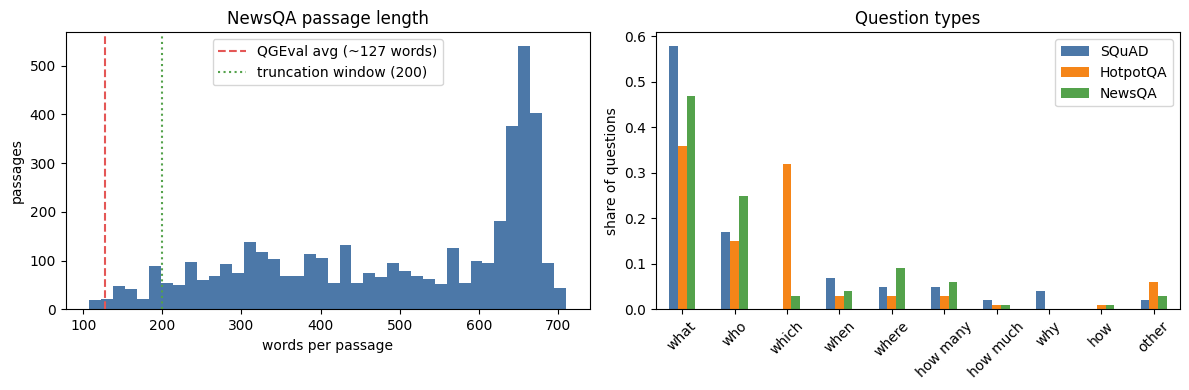

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(prof.p_words, bins=40, color="#4C78A8")
ax[0].axvline(127, color="#E45756", ls="--", label="QGEval avg (~127 words)")
ax[0].axvline(MAX_WORDS, color="#54A24B", ls=":", label=f"truncation window ({MAX_WORDS})")
ax[0].set(title="NewsQA passage length", xlabel="words per passage", ylabel="passages")
ax[0].legend()
qt[["SQuAD", "HotpotQA", "NewsQA"]].plot.bar(ax=ax[1], color=["#4C78A8", "#F58518", "#54A24B"])
ax[1].set(title="Question types", ylabel="share of questions"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.savefig("newsqa_properties.png", dpi=200); plt.show()

## Step 7 — Generate questions with two QG systems

In [8]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Same model families as QGEval systems M4 (T5-base-finetune) and M5 (T5-large-finetune),
# here public checkpoints fine-tuned on SQuAD by the lmqg project.
QG_MODELS = {"T5-base": "lmqg/t5-base-squad-qg", "T5-large": "lmqg/t5-large-squad-qg"}
device = "cuda" if torch.cuda.is_available() else "cpu"

def make_input(passage, answer):
    # lmqg models expect: "generate question: ... <hl> answer <hl> ..."
    return "generate question: " + passage.replace(answer, f"<hl> {answer} <hl>", 1)

inputs = [make_input(p, a) for p, a in zip(df.passage, df.answer)]
for name, ckpt in QG_MODELS.items():
    tok = AutoTokenizer.from_pretrained(ckpt)
    model = AutoModelForSeq2SeqLM.from_pretrained(ckpt).to(device).eval()
    out_q = []
    for i in range(0, len(inputs), 8):
        batch = tok(inputs[i:i + 8], return_tensors="pt", padding=True,
                    truncation=True, max_length=512).to(device)
        with torch.no_grad():
            out = model.generate(**batch, max_length=64, num_beams=4)
        out_q += tok.batch_decode(out, skip_special_tokens=True)
    df[f"q_{name}"] = [q.strip() for q in out_q]
    print(f"{name}: generated {len(out_q)} questions on {device}")
    del model; torch.cuda.empty_cache() if device == "cuda" else None

pd.set_option("display.max_colwidth", 70)
print(df[["id", "answer", "reference_question", "q_T5-base", "q_T5-large"]].head(8).to_string(index=False))

config.json:   0%|          | 0.00/1.54k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.44k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/20.0 [00:00<?, ?B/s]

... (16 outputs left out)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.95GB            

model.safetensors: downloading bytes:           |  0.00B            

T5-large: generated 100 questions on cuda
   id                                                                 answer                                           reference_question                                                                      q_T5-base                                                                     q_T5-large
NQ001                                             Lakes Golf Club in Sydney,                                         Where did they meet?                                            Where was the Australian Open held?                                            Where was the Australian Open held?
NQ002                                                                    two       All together, how many Golf developments Bulgaria has? How many courses have Gary Player overseen on the Black Sea coast in Bulgaria? How many golf courses has Gary Player overseen the development of in Bulgaria?
NQ003                                                  comic book char

## Step 8 — Score with QGEval's automatic metrics

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

Average metric score of generated questions vs the human reference question:

                            BLEU-4  ROUGE-L  METEOR  BERTScore
SQuAD T5-base (QGEval)       0.176    0.493   0.432      0.924
SQuAD T5-large (QGEval)      0.181    0.515   0.445      0.929
HotpotQA T5-base (QGEval)    0.160    0.441   0.425      0.903
HotpotQA T5-large (QGEval)   0.173    0.466   0.448      0.907
NewsQA T5-base (mine)        0.099    0.374   0.343      0.914
NewsQA T5-large (mine)       0.090    0.361   0.320      0.913


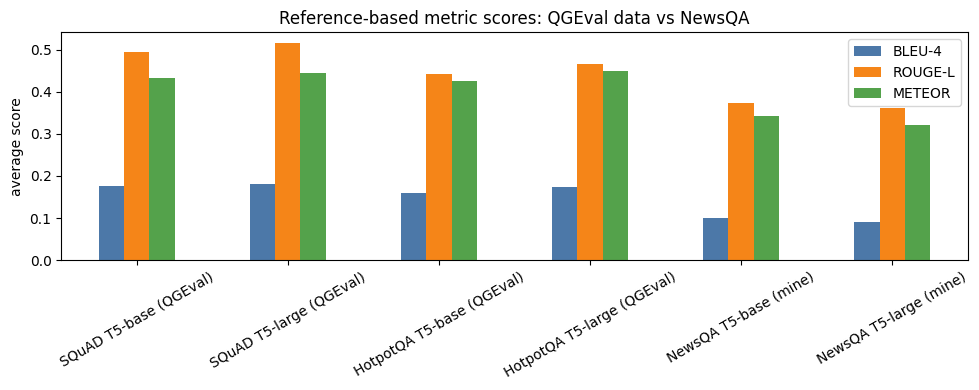

In [9]:
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer
from bert_score import score as bert_score
nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)

smooth = SmoothingFunction().method1
rs = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
METRICS = ["BLEU-4", "ROUGE-L", "METEOR", "BERTScore"]
ref = df.reference_question.tolist()
for name in QG_MODELS:
    hyp = df[f"q_{name}"].tolist()
    df[f"BLEU-4_{name}"] = [round(sentence_bleu([r.split(" ")], h.split(" "), smoothing_function=smooth), 4) for h, r in zip(hyp, ref)]
    df[f"ROUGE-L_{name}"] = [round(rs.score(h, r)["rougeL"].fmeasure, 4) for h, r in zip(hyp, ref)]
    df[f"METEOR_{name}"] = [round(meteor_score([r.split(" ")], h.split(" ")), 4) for h, r in zip(hyp, ref)]
    df[f"BERTScore_{name}"] = [round(x, 4) for x in bert_score(hyp, ref, lang="en", verbose=False)[2].tolist()]

compare = pd.DataFrame({
    "SQuAD T5-base (QGEval)":     [0.176, 0.493, 0.432, 0.924],
    "SQuAD T5-large (QGEval)":    [0.181, 0.515, 0.445, 0.929],
    "HotpotQA T5-base (QGEval)":  [0.160, 0.441, 0.425, 0.903],
    "HotpotQA T5-large (QGEval)": [0.173, 0.466, 0.448, 0.907],
    "NewsQA T5-base (mine)":  [round(df[f"{m}_T5-base"].mean(), 3) for m in METRICS],
    "NewsQA T5-large (mine)": [round(df[f"{m}_T5-large"].mean(), 3) for m in METRICS],
}, index=METRICS)
print("Average metric score of generated questions vs the human reference question:\n")
print(compare.T.to_string())

ax = compare.T[["BLEU-4", "ROUGE-L", "METEOR"]].plot.bar(figsize=(10, 4), color=["#4C78A8", "#F58518", "#54A24B"])
ax.set(title="Reference-based metric scores: QGEval data vs NewsQA", ylabel="average score")
ax.tick_params(axis="x", rotation=30); plt.tight_layout(); plt.savefig("newsqa_metric_comparison.png", dpi=200); plt.show()

## Step 9 — Annotation: build the blind scoring sheet
Following QGEval's method: **15 passages × 3 sources** (T5-base, T5-large, human reference) = 45 questions, **shuffled and with the source hidden**, to be scored 1–3 on all 7 dimensions. The key file is kept separately so the annotator can't see which system wrote which question.

In [10]:
ANNOTATE_PASSAGES = 15   # x 3 sources (T5-base, T5-large, human reference) = 45 questions
DIMS = ["fluency", "clarity", "conciseness", "relevance",
        "consistency", "answerability", "answer_consistency"]

picked = df.sample(ANNOTATE_PASSAGES, random_state=SEED)
rows = []
for _, r in picked.iterrows():
    for src, q in [("T5-base", r["q_T5-base"]), ("T5-large", r["q_T5-large"]),
                   ("reference", r["reference_question"])]:
        rows.append({"instance": r["id"], "source": src, "passage": r["passage"],
                     "answer": r["answer"], "question": q})
ann = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
ann.insert(0, "item", [f"A{i:02d}" for i in range(1, len(ann) + 1)])

key = ann[["item", "instance", "source"]]        # hidden from the annotator (blind, like QGEval)
sheet = ann[["item", "passage", "answer", "question"]].copy()
for d in DIMS:
    sheet[d] = ""
sheet["notes"] = ""

guide = pd.DataFrame({
    "dimension": DIMS,
    "question to ask": [
        "Is the question grammatical and readable?",
        "Is the meaning clear and unambiguous?",
        "Is it free of redundant or unnecessary words?",
        "Does it ask about important information in the passage?",
        "Does it agree with the passage (no contradiction or invented facts)?",
        "Can it be answered definitively from the passage?",
        "Is the given answer actually the answer to this question?"],
    "3": ["fully fluent", "fully clear", "concise", "relevant", "consistent", "definitively answerable", "answer matches"],
    "2": ["minor errors", "slightly vague", "some redundancy", "partly relevant", "minor inconsistency", "partly answerable", "partly matches"],
    "1": ["hard to read", "unclear", "very verbose", "irrelevant", "contradicts passage", "not answerable", "does not match"],
})
with pd.ExcelWriter("newsqa_annotation_sheet.xlsx") as xw:
    sheet.to_excel(xw, sheet_name="annotate", index=False)
    guide.to_excel(xw, sheet_name="scoring_guide", index=False)
key.to_csv("newsqa_annotation_key.csv", index=False)
print(f"Blind annotation sheet: {len(sheet)} questions ({ANNOTATE_PASSAGES} passages x 3 sources), shuffled")
print("Saved: newsqa_annotation_sheet.xlsx (blind scoring sheet) + newsqa_annotation_key.csv (source key, hidden during scoring)")

Blind annotation sheet: 45 questions (15 passages x 3 sources), shuffled
Saved: newsqa_annotation_sheet.xlsx (blind scoring sheet) + newsqa_annotation_key.csv (source key, hidden during scoring)


## Step 10 — Save files and dataset card

In [13]:
out_cols = ["id", "newsqa_key", "passage", "answer", "reference_question", "q_T5-base", "q_T5-large"] + \
           [f"{m}_{n}" for n in QG_MODELS for m in METRICS]
df[out_cols].to_csv("newsqa_qgeval_format.csv", index=False)
summary.to_csv("newsqa_properties.csv")
compare.to_csv("newsqa_metric_comparison.csv")

card = f"""# NewsQA-QGEval subset (dataset card)
**Source:** NewsQA (Trischler et al., 2017), CNN news articles; MRQA 2019 version on Hugging Face (lucadiliello/newsqa), validation split ({len(val):,} pairs).
**Purpose:** test whether QGEval's metric-human findings hold outside Wikipedia (domain generalisation).
**Preprocessing:** removed MRQA markers; kept answers of <= {MAX_ANSWER_WORDS} words found verbatim in the passage ({len(records):,} usable pairs); random sample of {SAMPLE_SIZE} (seed {SEED}); passages cut to a {MAX_WORDS}-word window centred on the answer ({n_trunc}/{SAMPLE_SIZE} truncated).
**Format:** QGEval format: passage, answer, reference question, plus questions from 2 QG systems (T5-base, T5-large fine-tuned on SQuAD) and 4 automatic metric scores each.
**Properties:** avg full article {summary.loc['Avg passage words', 'NewsQA validation (full)']} words vs ~127 in QGEval; question-passage overlap {summary.loc['Question-passage word overlap', 'NewsQA validation (full)']} vs 0.65 (SQuAD).
**Annotation:** blind, shuffled sheet of 45 questions (15 passages x 3 sources: T5-base, T5-large, human reference); 15 questions (5 passages x 3 sources) scored by a human annotator and all 45 by an LLM judge, on QGEval's 7 dimensions (1-3 scale).
**Complexity:** articles are ~4x longer than QGEval passages, so a 200-word window around the answer is used; questions are much shorter (6.5 vs 10-15 words) and were written from article summaries, so many are underspecified without the article; answers usually appear early in the article, in the news lead.
"""
open("newsqa_dataset_card.md", "w").write(card)
print(card)

from google.colab import files
for f in ["newsqa_qgeval_format.csv", "newsqa_properties.csv", "newsqa_metric_comparison.csv",
          "newsqa_annotation_sheet.xlsx", "newsqa_annotation_key.csv", "newsqa_dataset_card.md",
          "newsqa_properties.png", "newsqa_metric_comparison.png"]:
    files.download(f)

# NewsQA-QGEval subset (dataset card)
**Source:** NewsQA (Trischler et al., 2017), CNN news articles; MRQA 2019 version on Hugging Face (lucadiliello/newsqa), validation split (4,212 pairs).
**Purpose:** test whether QGEval's metric-human findings hold outside Wikipedia (domain generalisation).
**Preprocessing:** removed MRQA markers; kept answers of <= 10 words found verbatim in the passage (3,902 usable pairs); random sample of 100 (seed 42); passages cut to a 200-word window centred on the answer (95/100 truncated).
**Format:** QGEval format: passage, answer, reference question, plus questions from 2 QG systems (T5-base, T5-large fine-tuned on SQuAD) and 4 automatic metric scores each.
**Properties:** avg full article 492.6 words vs ~127 in QGEval; question-passage overlap 0.72 vs 0.65 (SQuAD).
**Annotation:** blind, shuffled sheet of 45 questions (15 passages x 3 sources) scored 1-3 on QGEval's 7 dimensions.
**Complexity:** articles are ~4x longer than QGEval passages, so a 200-wor